## 1. Setup: Paths, Utilities, and Shared Functions

In [117]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

_ = plt

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def resolve_data_root() -> Path:
    candidates = [Path("./")]
    for candidate in candidates:
        if candidate.exists():
            return candidate


def resolve_rsigma_root() -> Path:
    rsigma_root = resolve_data_root() / "RSigma"
    rsigma_root.mkdir(parents=True, exist_ok=True)
    return rsigma_root


def compute_rsigma_from_xvta(xvta: np.ndarray):
    n_timesteps, _, n_particles = xvta.shape
    com_2d = np.mean(xvta[:, :2, :], axis=2)
    radii = np.sqrt(np.sum((xvta[:, :2, :] - com_2d[:, :, None]) ** 2, axis=1))
    r_half = np.sort(radii, axis=1)[:, n_particles // 2]
    sigma_v = np.mean(np.std(xvta[:, 3:, :], axis=2), axis=1)
    t_vals = np.linspace(0, 11, n_timesteps)
    return r_half, sigma_v, t_vals


def compute_soliton_core_radius(m_a: float, M: float = 1e9, r_setup_res: int = 512) -> float:
    r_setup = np.logspace(-3, 3, r_setup_res)
    a = 10.0
    alpha = 1.0 / 3.0
    rho_arr = M / (2.0 * np.pi * a**3) / (r_setup / a) / (1.0 + r_setup / a) ** 3
    rc = 1.6 * (m_a / 1e-22) ** -1 * (M / 1e9) ** (-alpha)
    rhoc = 0.019 * (m_a / 1e-22) ** -2 * rc**-4 / (1.0 + 0.091 * (r_setup / rc) ** 2) ** 8 * 1e9
    transition = np.max(np.where(rhoc > rho_arr)) + 1
    return r_setup[transition]


def load_rsigma_series(rsigma_root: Path, dataset_name: str, seed: int, r_ic: str):
    npz_path = rsigma_root / dataset_name / f"s{seed}" / f"xvta_Ric{r_ic}.npz"
    if not npz_path.exists():
        return None

    with np.load(npz_path) as data:
        if not all(key in data for key in ("R_half", "sigma_v", "t_vals")):
            return None
        r_half = data["R_half"]
        sigma_v = data["sigma_v"]
        t_vals = data["t_vals"]

    return r_half, sigma_v, t_vals


def collect_rsigma_for_case(rsigma_root: Path, dataset_name: str, seeds, r_ic: str):
    all_r, all_v, all_t = [], [], []
    for seed in seeds:
        loaded = load_rsigma_series(rsigma_root, dataset_name, seed, r_ic)
        if loaded is None:
            continue
        r_half, sigma_v, t_vals = loaded
        all_r.append(r_half)
        all_v.append(sigma_v)
        all_t.append(t_vals)
    return all_r, all_v, all_t


def trimmed_mean(series_list):
    if not series_list:
        return None, 0
    min_len = min(len(series) for series in series_list)
    stacked = np.array([series[:min_len] for series in series_list])
    return np.mean(stacked, axis=0), min_len


def trimmed_time(t_list, target_len: int):
    if not t_list:
        return np.arange(target_len)
    return t_list[0][:target_len]


def fit_growth_and_plateau(t_vals, y_vals, r_transition):
    mask = t_vals >= 1.0
    t = t_vals[mask]
    y = y_vals[mask]

    if len(t) < 5:
        return 0.0, 0.0, None

    idx_trans = np.where(y > r_transition)[0]

    if len(idx_trans) == 0:
        k, b = np.polyfit(t, np.log(y), 1)
        y_fit = np.exp(k * t + b)
        return k, 0.0, (t, y_fit, None, None)

    i_trans = idx_trans[0]
    t_fit = t[:i_trans]
    y_fit_data = y[:i_trans]

    if len(t_fit) >= 5:
        k, b = np.polyfit(t_fit, np.log(y_fit_data), 1)
        y_fit = np.exp(k * t_fit + b)
    else:
        k, y_fit = 0.0, None

    t_plateau = t[i_trans:]
    y_plateau = y[i_trans:]

    if len(y_plateau) >= 5:
        c = float(np.mean(y_plateau))
    else:
        c = 0.0
        t_plateau = None

    return k, c, (t_fit, y_fit, t_plateau, c)


def format_sci_tex(x):
    if x == 0:
        return "0"
    coeff, exp = f"{x:.1e}".split("e")
    return rf"{float(coeff):g}\times10^{{{int(exp)}}}"

## 2. Build RSigma Cache from All xvta NPZ Files

In [118]:
data_root = resolve_data_root()
rsigma_root = resolve_rsigma_root()

processed = 0
skipped_existing = 0
skipped_no_xvta = 0
failed = 0

for npz_path in sorted(data_root.rglob("*.npz")):
    if "RSigma" in npz_path.parts:
        continue

    save_path = rsigma_root / npz_path.relative_to(data_root)
    if save_path.exists():
        skipped_existing += 1
        continue

    try:
        with np.load(npz_path) as data:
            if "xvta" not in data:
                skipped_no_xvta += 1
                continue
            xvta = data["xvta"]

        r_half, sigma_v, t_vals = compute_rsigma_from_xvta(xvta)

        save_path.parent.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(
            save_path,
            R_half=r_half,
            sigma_v=sigma_v,
            t_vals=t_vals,
            source_file=str(npz_path),
        )
        processed += 1

    except Exception as exc:
        failed += 1
        print(f"[FAILED] {npz_path}: {exc}")

print(f"Data root         : {data_root}")
print(f"RSigma root       : {rsigma_root}")
print(f"Processed         : {processed}")
print(f"Skipped existing  : {skipped_existing} (already in RSigma)")
print(f"Skipped no xvta   : {skipped_no_xvta} (missing 'xvta' key)")
print(f"Failed            : {failed}")

Data root         : .
RSigma root       : RSigma
Processed         : 0
Skipped existing  : 6 (already in RSigma)
Skipped no xvta   : 31 (missing 'xvta' key)
Failed            : 0


## 3. Plot A: Soliton vs No-Soliton (m_a = 1.0e-22)

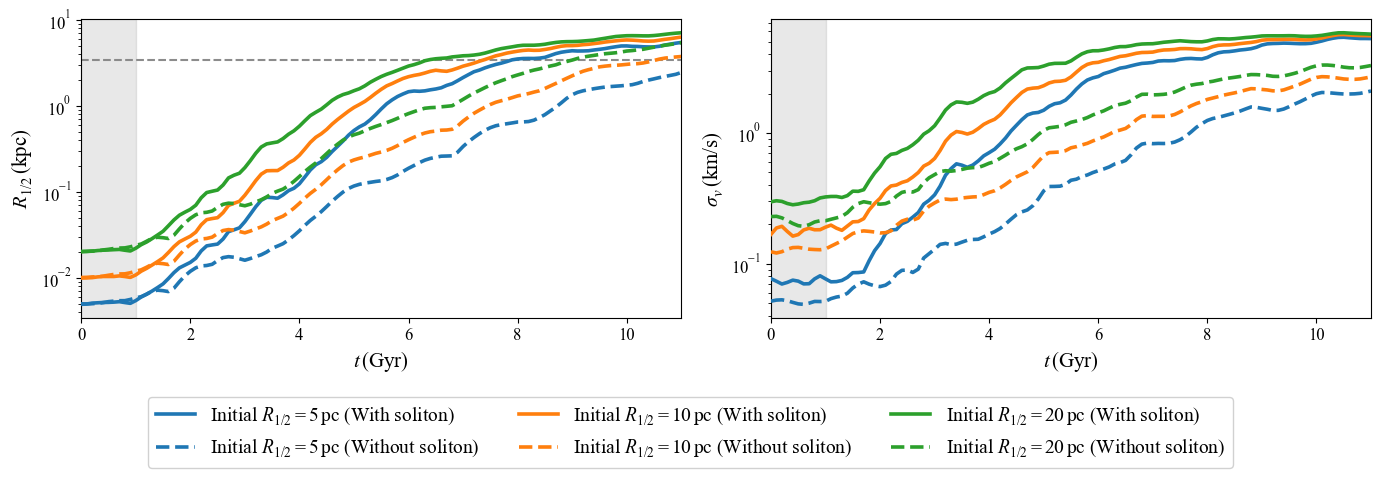

In [119]:
plt.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "font.size": 13,
        "axes.labelsize": 15,
        "axes.titlesize": 14,
        "legend.fontsize": 11,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "axes.unicode_minus": False,
    }
)

m_as = [1.0e-22]
M = 1e9
t_step = 0.1
seeds = np.arange(20)
rsigma_root = resolve_rsigma_root()

for m_a in m_as:
    r_core = compute_soliton_core_radius(m_a, M=M)
    base_folder = f"ma{m_a:.1e}M{M:.1e}ts{t_step}rres512"
    folders = {
        "With soliton": base_folder,
        "Without soliton": base_folder + "_nosoliton",
    }
    line_styles = {"With soliton": "-", "Without soliton": "--"}

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    R_ic_colors = {"5pc": "#1f77b4", "10pc": "#ff7f0e", "20pc": "#2ca02c"}
    R_ic_labels = {
        "5pc": r"Initial $R_{1/2}=5\,\mathrm{pc}$",
        "10pc": r"Initial $R_{1/2}=10\,\mathrm{pc}$",
        "20pc": r"Initial $R_{1/2}=20\,\mathrm{pc}$",
    }

    for r_ic in ["5pc", "10pc", "20pc"]:
        color = R_ic_colors[r_ic]

        for case_name, dataset_name in folders.items():
            all_r, all_v, all_t = collect_rsigma_for_case(rsigma_root, dataset_name, seeds, r_ic)
            if not all_r:
                continue

            mean_r, min_len = trimmed_mean(all_r)
            mean_v, _ = trimmed_mean(all_v)
            t_ref = trimmed_time(all_t, min_len)

            plot_label = f"{R_ic_labels[r_ic]} ({case_name})"
            axes[0].plot(
                t_ref,
                mean_r,
                color=color,
                linestyle=line_styles[case_name],
                linewidth=2.6,
                label=plot_label,
                zorder=10,
            )
            axes[1].plot(
                t_ref,
                mean_v,
                color=color,
                linestyle=line_styles[case_name],
                linewidth=2.6,
                zorder=10,
            )

    axes[0].set_ylabel(r"$R_{1/2}\,(\mathrm{kpc})$")
    axes[0].set_yscale("log")
    axes[1].set_ylabel(r"$\sigma_v\,(\mathrm{km/s})$")
    axes[1].set_yscale("log")

    axes[0].set_xlabel(r"$t\,(\mathrm{Gyr})$")
    axes[1].set_xlabel(r"$t\,(\mathrm{Gyr})$")
    axes[0].set_xlim(0, 11)
    axes[1].set_xlim(0, 11)
    axes[0].axvspan(0.0, 1.0, color="gray", alpha=0.18, zorder=0)
    axes[1].axvspan(0.0, 1.0, color="gray", alpha=0.18, zorder=0)

    axes[0].axhline(r_core, color="gray", linestyle="--", linewidth=1.5, alpha=0.9)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.015),
        ncol=3,
        frameon=True,
        framealpha=0.9,
        fontsize=14,
    )

    plt.tight_layout(rect=[0, 0.16, 1, 1])
    plt.savefig(FIGURES_DIR / "plot_a_soliton_vs_no_soliton_ma1e-22.png", dpi=300, bbox_inches="tight")
    plt.show()

## 4. Plot B: Combined Evolution for Multiple m_a

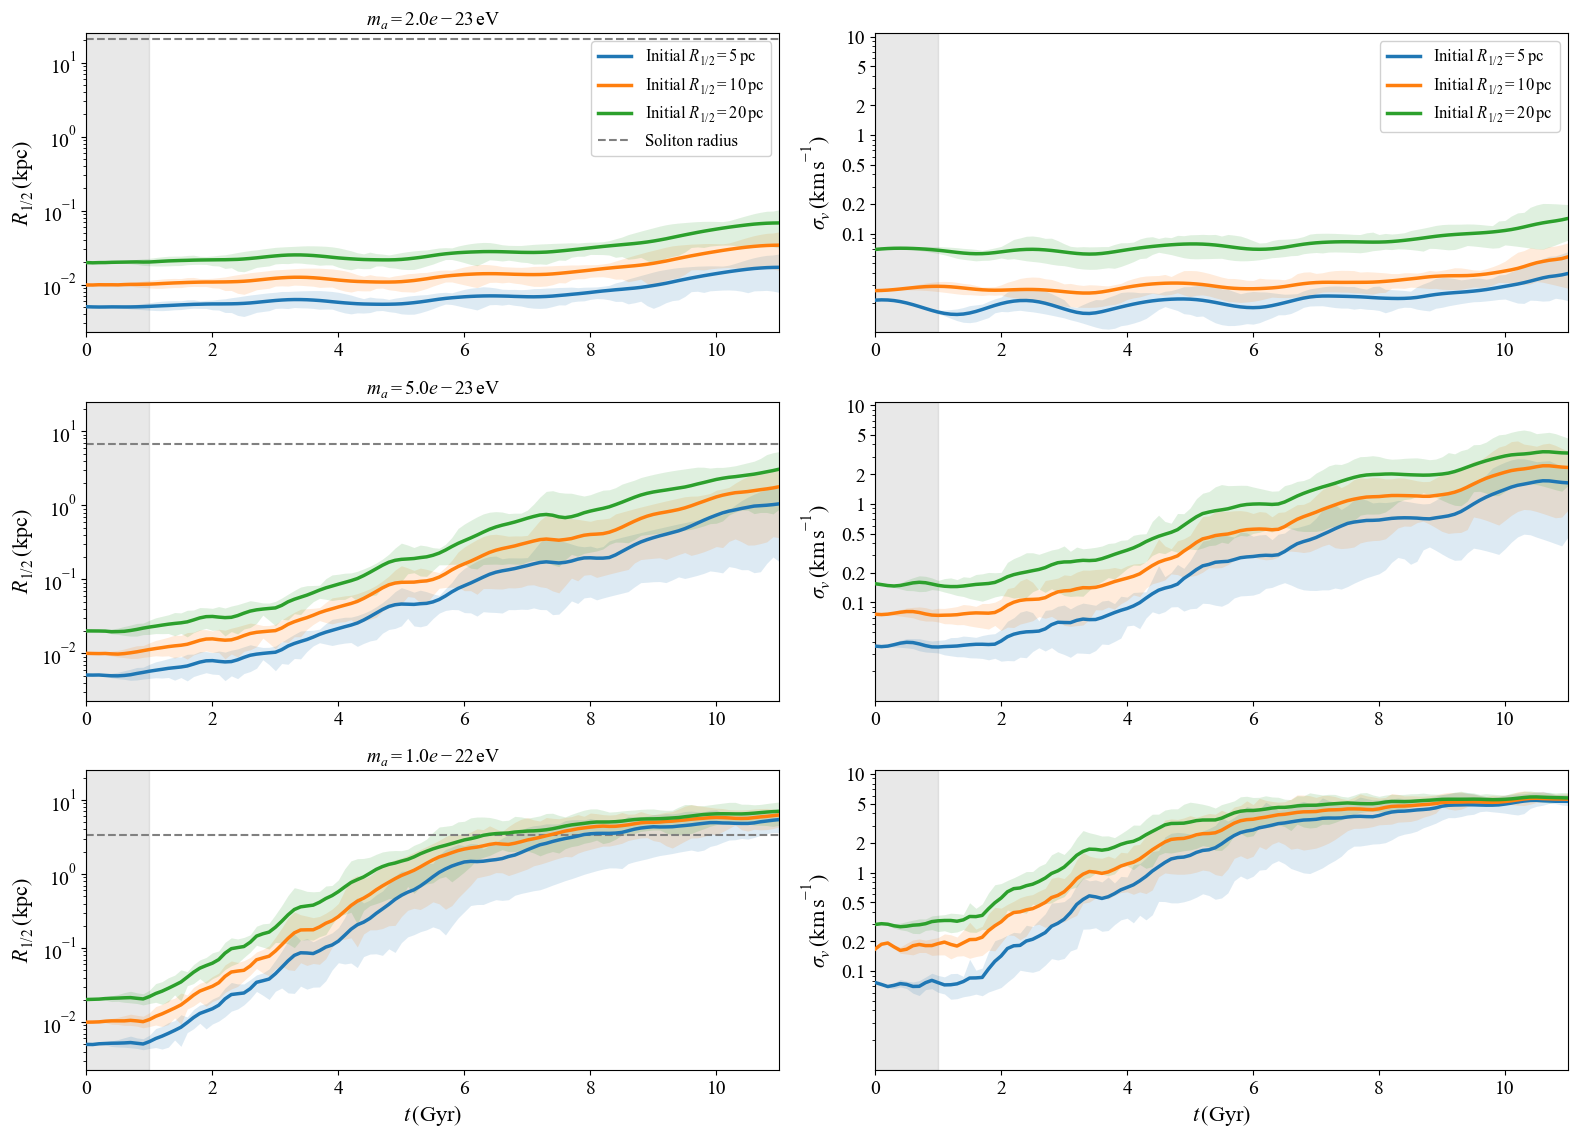

In [120]:
plt.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "font.size": 14,
        "axes.labelsize": 16,
        "axes.titlesize": 14,
        "legend.fontsize": 12,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "axes.unicode_minus": False,
    }
)

m_as = [0.2e-22, 0.5e-22, 1.0e-22]
have_soliton = True
M = 1e9
t_step = 0.1
seeds = np.arange(20)
rsigma_root = resolve_rsigma_root()

n_masses = len(m_as)
fig, axes = plt.subplots(n_masses, 2, figsize=(16, 4 * n_masses))

R_ic_colors = {"5pc": "#1f77b4", "10pc": "#ff7f0e", "20pc": "#2ca02c"}
R_ic_labels = {
    "5pc": r"Initial $R_{1/2}=5\,\mathrm{pc}$",
    "10pc": r"Initial $R_{1/2}=10\,\mathrm{pc}$",
    "20pc": r"Initial $R_{1/2}=20\,\mathrm{pc}$",
}

global_r_min, global_r_max = np.inf, 0.0
global_v_min, global_v_max = np.inf, 0.0
soliton_radii = []

for idx, m_a in enumerate(m_as):
    r_core = compute_soliton_core_radius(m_a, M=M)
    if have_soliton:
        soliton_radii.append(float(r_core))

    dataset_name = f"ma{m_a:.1e}M{M:.1e}ts{t_step}rres512"
    if not have_soliton:
        dataset_name += "_nosoliton"

    ax_r = axes[idx, 0]
    ax_sigma = axes[idx, 1]

    for r_ic in ["5pc", "10pc", "20pc"]:
        color = R_ic_colors[r_ic]
        label = R_ic_labels[r_ic]

        all_r, all_v, all_t = collect_rsigma_for_case(rsigma_root, dataset_name, seeds, r_ic)

        if all_r:
            min_len = min(len(series) for series in all_r)
            r_stack = np.array([series[:min_len] for series in all_r], dtype=float)
            v_stack = np.array([series[:min_len] for series in all_v], dtype=float)
            t_ref = trimmed_time(all_t, min_len)

            r_p16 = np.percentile(r_stack, 16, axis=0)
            r_p84 = np.percentile(r_stack, 84, axis=0)
            v_p16 = np.percentile(v_stack, 16, axis=0)
            v_p84 = np.percentile(v_stack, 84, axis=0)

            ax_r.fill_between(t_ref, r_p16, r_p84, color=color, alpha=0.15, linewidth=0, zorder=2)
            ax_sigma.fill_between(t_ref, v_p16, v_p84, color=color, alpha=0.15, linewidth=0, zorder=2)

            mean_r = np.mean(r_stack, axis=0)
            mean_v = np.mean(v_stack, axis=0)
            ax_r.plot(t_ref, mean_r, color=color, linewidth=2.5, label=label, zorder=10)
            ax_sigma.plot(t_ref, mean_v, color=color, linewidth=2.5, label=label, zorder=10)

            r_pos = r_stack[r_stack > 0]
            v_pos = v_stack[v_stack > 0]
            if r_pos.size:
                global_r_min = min(global_r_min, float(np.min(r_pos)))
                global_r_max = max(global_r_max, float(np.max(r_pos)))
            if v_pos.size:
                global_v_min = min(global_v_min, float(np.min(v_pos)))
                global_v_max = max(global_v_max, float(np.max(v_pos)))

    if have_soliton:
        ax_r.axhline(
            r_core,
            color="gray",
            linestyle="--",
            linewidth=1.5,
            label="Soliton radius" if idx == 0 else None,
        )

    ax_r.set_ylabel(r"$R_{1/2}\,(\mathrm{kpc})$", fontsize=16)
    ax_r.set_yscale("log")
    ax_r.set_title(rf"$m_a = {m_a:.1e}\,\mathrm{{eV}}$", fontsize=14)

    ax_sigma.set_ylabel(r"$\sigma_v\,(\mathrm{km\,s^{-1}})$", fontsize=16)
    ax_sigma.set_yscale("log")

    if idx == n_masses - 1:
        ax_r.set_xlabel(r"$t\,(\mathrm{Gyr})$", fontsize=16)
        ax_sigma.set_xlabel(r"$t\,(\mathrm{Gyr})$", fontsize=16)

    ax_r.set_xlim(0, 11)
    ax_sigma.set_xlim(0, 11)
    ax_r.axvspan(0.0, 1.0, color="gray", alpha=0.18, zorder=0)
    ax_sigma.axvspan(0.0, 1.0, color="gray", alpha=0.18, zorder=0)

if not np.isfinite(global_r_min):
    global_r_min, global_r_max = 1e-3, 1e1
if not np.isfinite(global_v_min):
    global_v_min, global_v_max = 1e-2, 1e1

r_upper = global_r_max
if have_soliton and soliton_radii:
    r_upper = max(r_upper, max(soliton_radii))

r_ylim = (max(global_r_min * 0.8, 1e-4), r_upper * 1.2)
v_ylim = (max(global_v_min * 0.8, 1e-2), max(global_v_max * 1.15, 10.0))
sigma_ticks = [tick for tick in [0.1, 0.2, 0.5, 1, 2, 5, 10] if v_ylim[0] <= tick <= v_ylim[1]]

for idx in range(n_masses):
    axes[idx, 0].set_ylim(*r_ylim)
    axes[idx, 1].set_ylim(*v_ylim)
    if sigma_ticks:
        axes[idx, 1].set_yticks(sigma_ticks)
        axes[idx, 1].set_yticklabels([f"{tick:g}" for tick in sigma_ticks])

if n_masses > 0:
    axes[0, 0].legend(loc="best", frameon=True, framealpha=0.9, fontsize=12)
    axes[0, 1].legend(loc="best", frameon=True, framealpha=0.9, fontsize=12)

plt.tight_layout()
plt.subplots_adjust(top=0.93)
plt.savefig(FIGURES_DIR / "plot_b_combined_evolution_all_masses.png", dpi=150, bbox_inches="tight")
plt.show()

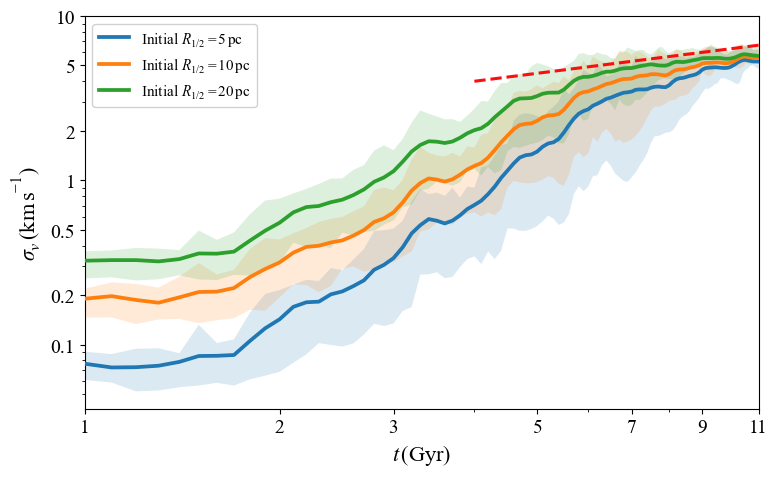

In [121]:
m_a = 1.0e-22
M = 1e9
t_step = 0.1
seeds = np.arange(20)
rsigma_root = resolve_rsigma_root()
dataset_name = f"ma{m_a:.1e}M{M:.1e}ts{t_step}rres512"
r_core = compute_soliton_core_radius(m_a, M=M)
import matplotlib.ticker as mticker

fig, ax = plt.subplots(1, 1, figsize=(8, 5))

R_ic_colors = {"5pc": "#1f77b4", "10pc": "#ff7f0e", "20pc": "#2ca02c"}
R_ic_labels = {
    "5pc": r"Initial $R_{1/2}=5\,\mathrm{pc}$",
    "10pc": r"Initial $R_{1/2}=10\,\mathrm{pc}$",
    "20pc": r"Initial $R_{1/2}=20\,\mathrm{pc}$",
}

guide_candidates = []

for r_ic in ["5pc", "10pc", "20pc"]:
    color = R_ic_colors[r_ic]
    label = R_ic_labels[r_ic]

    all_r, all_v, all_t = collect_rsigma_for_case(rsigma_root, dataset_name, seeds, r_ic)
    if (not all_r) or (not all_v):
        continue

    min_len_r = min(len(series) for series in all_r)
    min_len_v = min(len(series) for series in all_v)
    min_len = min(min_len_r, min_len_v)

    r_stack = np.array([series[:min_len] for series in all_r], dtype=float)
    v_stack = np.array([series[:min_len] for series in all_v], dtype=float)
    t_ref = trimmed_time(all_t, min_len)

    mean_r = np.mean(r_stack, axis=0)
    mean_v = np.mean(v_stack, axis=0)
    v_p16 = np.percentile(v_stack, 16, axis=0)
    v_p84 = np.percentile(v_stack, 84, axis=0)

    valid_mask = (t_ref > 0) & (mean_r > 0) & (mean_v > 0) & (v_p16 > 0) & (v_p84 > 0)
    if not np.any(valid_mask):
        continue

    t_plot = t_ref[valid_mask]
    mean_r_plot = mean_r[valid_mask]
    mean_v_plot = mean_v[valid_mask]
    v_p16_plot = v_p16[valid_mask]
    v_p84_plot = v_p84[valid_mask]

    ax.fill_between(t_plot, v_p16_plot, v_p84_plot, color=color, alpha=0.16, linewidth=0, zorder=2)
    ax.plot(t_plot, mean_v_plot, color=color, linewidth=2.7, label=label, zorder=10)

    reach_idx = np.where(mean_r_plot >= r_core)[0]
    if reach_idx.size == 0:
        continue

    i0 = int(reach_idx[0])
    t_start = float(t_plot[i0])

    if i0 > 0:
        t0 = float(t_plot[i0 - 1])
        t1 = float(t_plot[i0])
        r0 = float(mean_r_plot[i0 - 1])
        r1 = float(mean_r_plot[i0])
        if r1 != r0:
            frac = (r_core - r0) / (r1 - r0)
            frac = float(np.clip(frac, 0.0, 1.0))
            t_start = t0 + frac * (t1 - t0)

    t_start = float(np.clip(t_start, 0.1, 10.0))
    if t_start >= 10.0:
        continue

    sigma_start = float(np.interp(t_start, t_plot, mean_v_plot))
    guide_candidates.append((t_start, sigma_start))

if guide_candidates:
    t_cross = np.array([item[0] for item in guide_candidates], dtype=float)
    sigma_cross = np.array([item[1] for item in guide_candidates], dtype=float)

    t_line_start = 4
    t_anchor = float(np.median(np.clip(t_cross, 1.0, 10.0)))
    t_anchor = max(t_anchor, 1e-6)
    sigma_anchor = float(np.median(sigma_cross))

    # Lift the guide line slightly so it serves as a visual trend indicator.
    sigma_line_start = sigma_anchor * np.sqrt(t_line_start / t_anchor) * 1.25

    t_guide = np.linspace(t_line_start, 11.0, 180)
    sigma_guide = sigma_line_start * np.sqrt(t_guide / t_line_start)

    ax.plot(
        t_guide,
        sigma_guide,
        linestyle="--",
        color="red",
        linewidth=2.2,
        alpha=0.95,
        zorder=11,
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1.0, 11.0)

# Use plain-number tick labels for a cleaner look on log axes.
ax.set_xticks([1, 2, 3, 5, 7, 9, 11])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}" if 1.0 <= x <= 11.0 else ""))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())

ax.set_yticks([0.1, 0.2, 0.5, 1, 2, 5, 10])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{y:g}" if y > 0 else ""))
ax.yaxis.set_minor_formatter(mticker.NullFormatter())

ax.set_xlabel(r"$t\,(\mathrm{Gyr})$")
ax.set_ylabel(r"$\sigma_v\,(\mathrm{km\,s^{-1}})$")

ax.legend(loc="upper left", frameon=True, framealpha=0.9, fontsize=11)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "plot_b_sigma_vs_rhalf_ma1e-22_loglog.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Plot C-D: Main Fit and k_vs_m_a

Plot D linear-fit slopes:
  k_R vs m_a: 1.2085 Gyr^-1 (10^-22 eV)^-1
  k_sigma vs m_a: 0.7278 Gyr^-1 (10^-22 eV)^-1


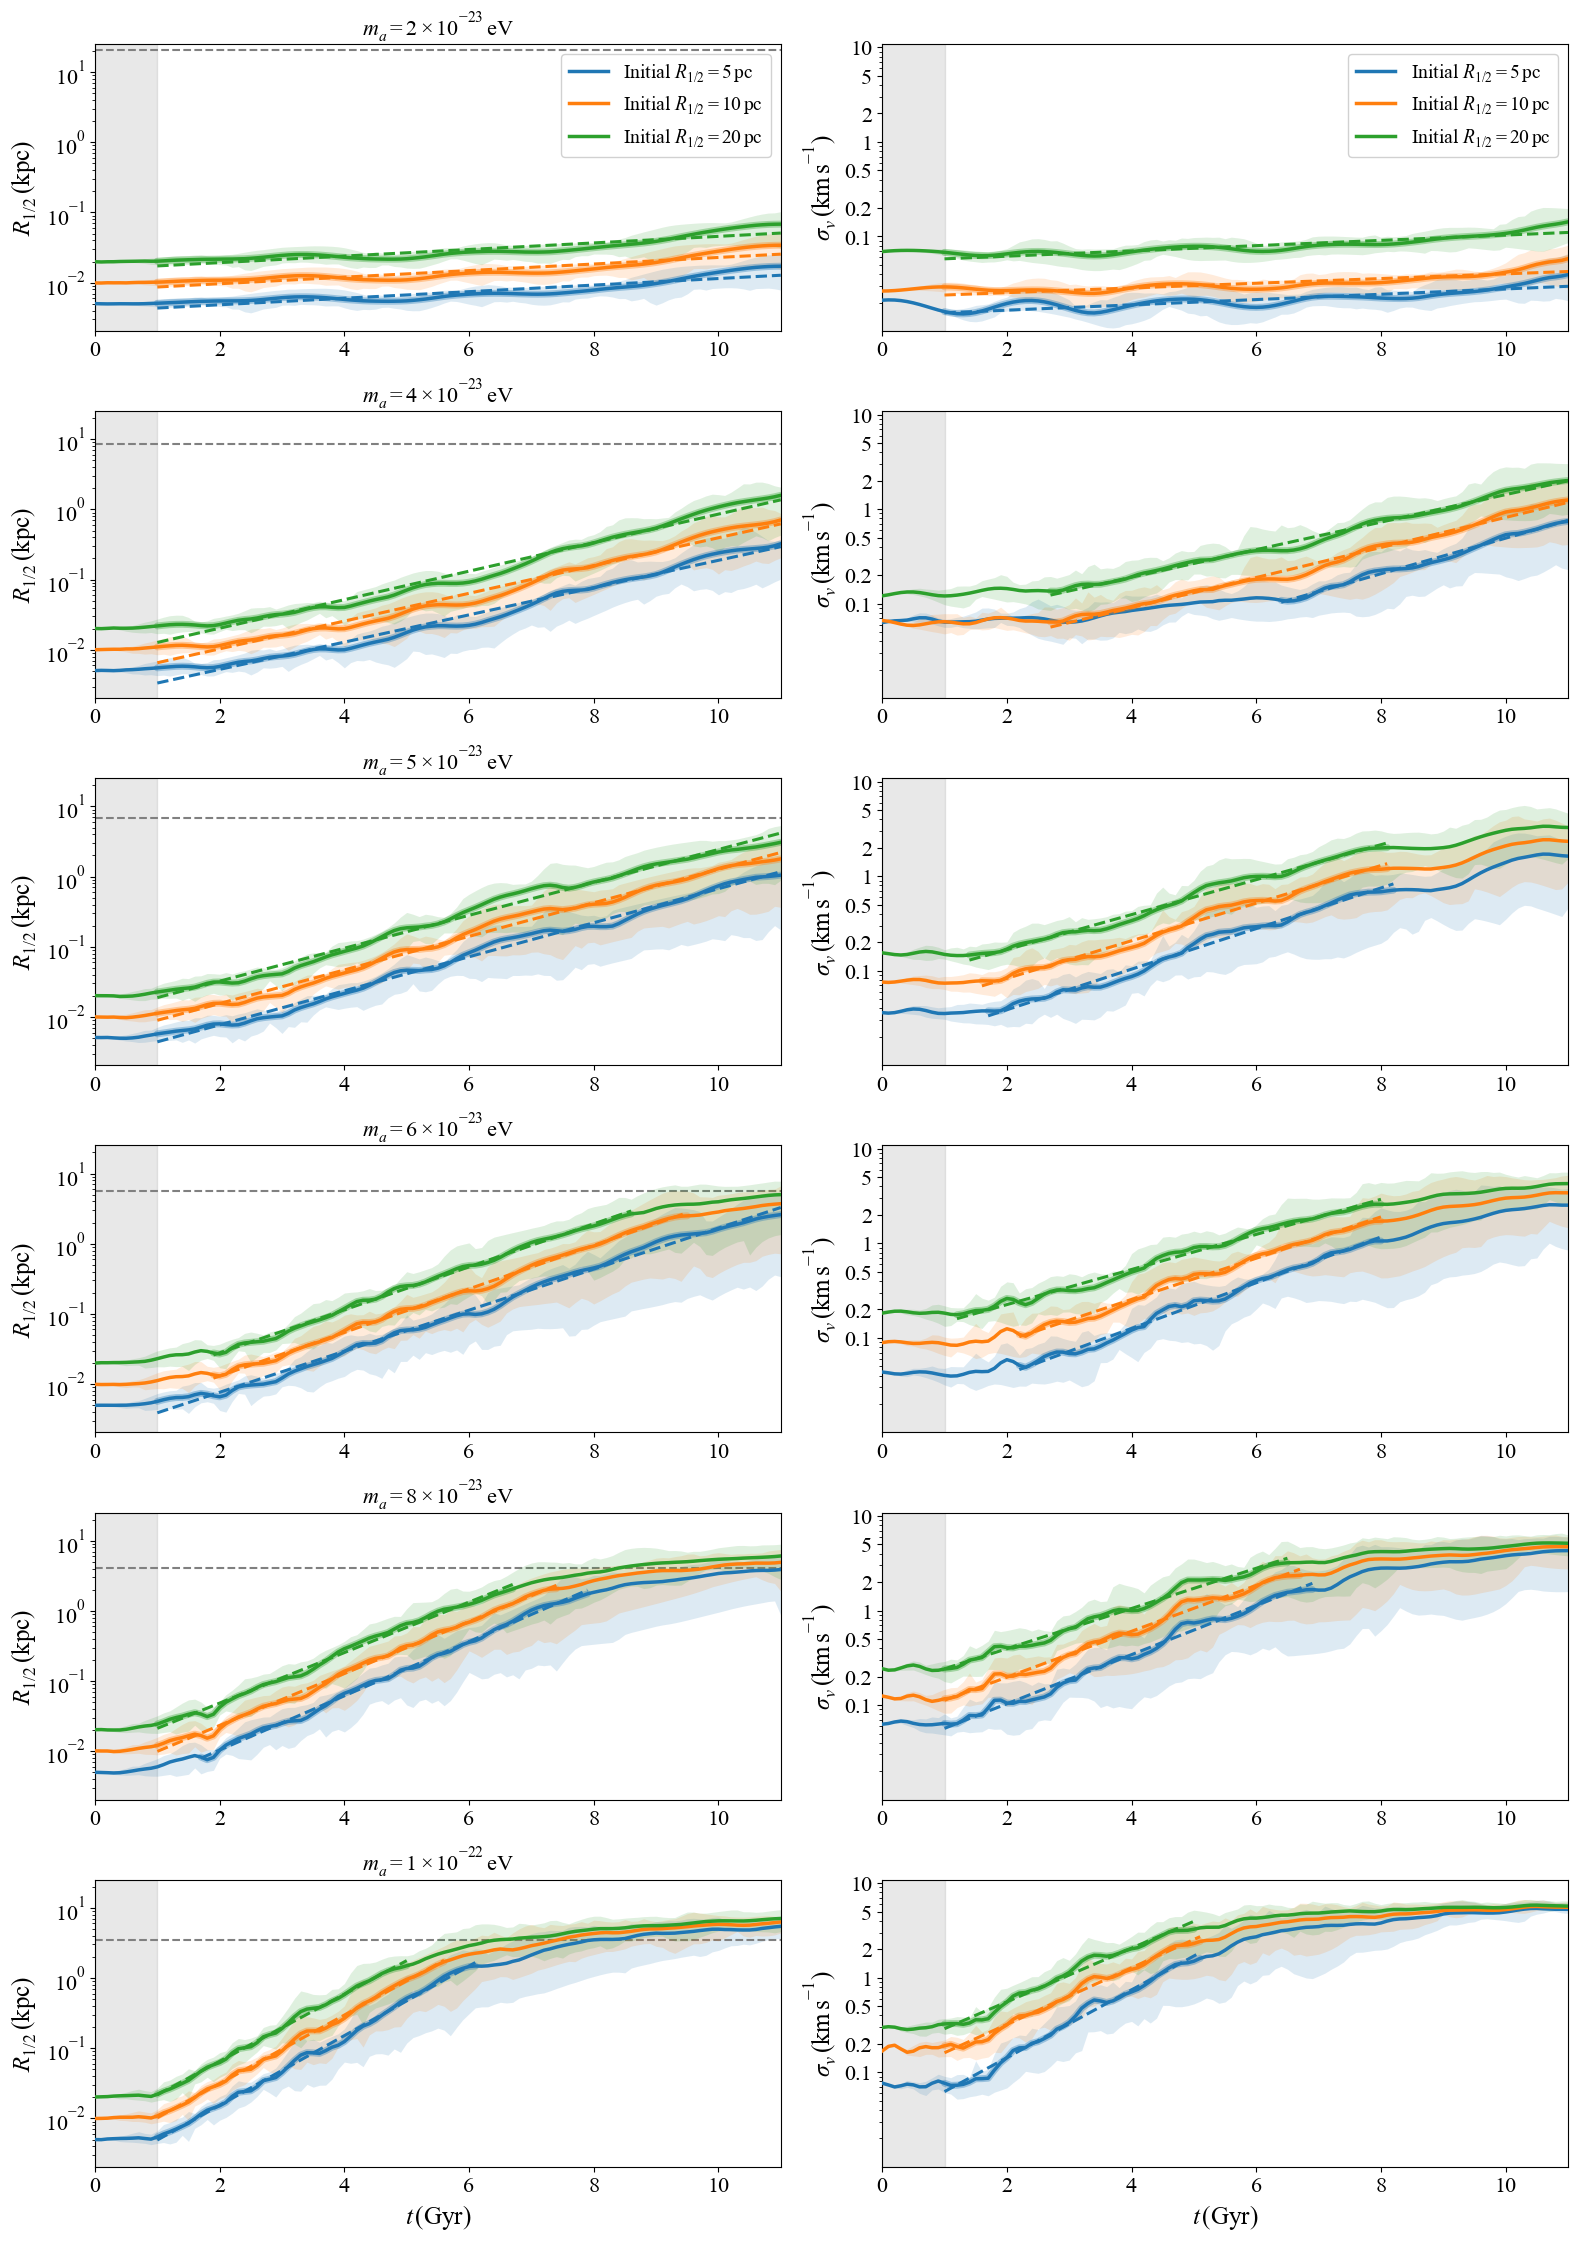

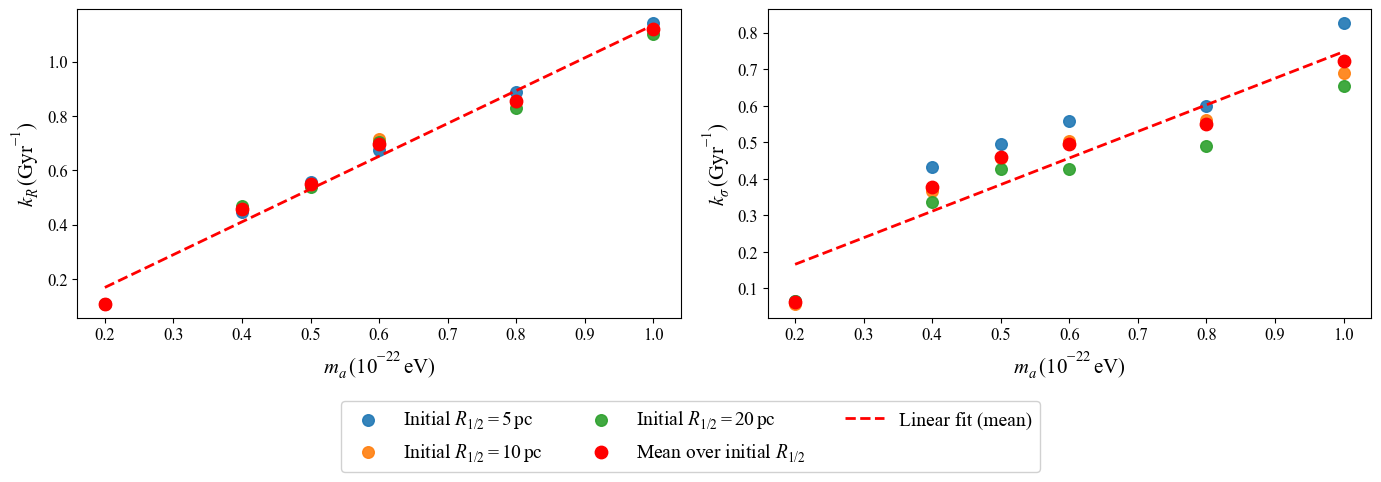

In [122]:
plt.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "font.size": 14,
        "axes.labelsize": 16,
        "axes.titlesize": 14,
        "legend.fontsize": 12,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "axes.unicode_minus": False,
    }
)

m_as = [0.2e-22, 0.4e-22, 0.5e-22, 0.6e-22, 0.8e-22, 1.0e-22]
have_soliton = True
M = 1e9
t_step = 0.1
seeds = np.arange(20)
rsigma_root = resolve_rsigma_root()

R_ic_list = ["5pc", "10pc", "20pc"]
R_ic_colors = {"5pc": "#1f77b4", "10pc": "#ff7f0e", "20pc": "#2ca02c"}
R_ic_labels = {
    "5pc": r"Initial $R_{1/2}=5\,\mathrm{pc}$",
    "10pc": r"Initial $R_{1/2}=10\,\mathrm{pc}$",
    "20pc": r"Initial $R_{1/2}=20\,\mathrm{pc}$",
}

MIN_RHALF_FIT_DURATION = 4.0
MIN_SIGMA_FIT_DURATION = 4.0
FIT_START_TIME = 1.0
FIT_END_TIME = 11.0
FORCE_FULL_RHALF_LIMIT = 0.1
SOLITON_FIT_FRACTION = 0.5


def _fit_log_linear(t, y):
    k, b = np.polyfit(t, np.log(y), 1)
    return k, b, np.exp(k * t + b)


def _crossing_time(t, y, level):
    idx = np.where(y >= level)[0]
    if idx.size == 0:
        return None

    i1 = int(idx[0])
    if i1 == 0:
        return float(t[0])

    t0, t1 = float(t[i1 - 1]), float(t[i1])
    y0, y1 = float(y[i1 - 1]), float(y[i1])
    if y1 == y0:
        return t1

    frac = np.clip((level - y0) / (y1 - y0), 0.0, 1.0)
    return float(t0 + frac * (t1 - t0))


def _prepare_fit_data(t_vals, y_vals):
    t = np.asarray(t_vals, dtype=float)
    y = np.asarray(y_vals, dtype=float)
    mask = (t >= FIT_START_TIME) & (t <= FIT_END_TIME) & np.isfinite(t) & np.isfinite(y) & (y > 0)
    return t[mask], y[mask]


def _fit_selected_window(t, y, i0, i1, mode, min_duration):
    if i0 is None or i1 is None or i1 <= i0:
        return np.nan, 0.0, None

    t_seg = t[i0 : i1 + 1]
    y_seg = y[i0 : i1 + 1]
    if len(t_seg) < 3 or (t_seg[-1] - t_seg[0]) < min_duration:
        return np.nan, 0.0, None

    k, b, y_fit = _fit_log_linear(t_seg, y_seg)
    return float(k), 0.0, {
        "mode": mode,
        "t_data": t_seg,
        "y_data": y_seg,
        "t_fit": t_seg,
        "y_fit": y_fit,
    }


def _fit_entire_segment(t, y, mode, min_duration):
    return _fit_selected_window(t, y, 0, len(t) - 1, mode, min_duration)


def _most_linear_window_indices(t, y, min_duration):
    if len(t) < 3 or (t[-1] - t[0]) < min_duration:
        return None, None

    best = None
    log_y = np.log(y)
    n = len(t)
    for i0 in range(n - 2):
        for i1 in range(i0 + 2, n):
            duration = t[i1] - t[i0]
            if duration < min_duration:
                continue

            tt = t[i0 : i1 + 1]
            yy_log = log_y[i0 : i1 + 1]
            k, b = np.polyfit(tt, yy_log, 1)
            pred = k * tt + b
            residual = yy_log - pred
            ss_res = float(np.sum(residual**2))
            ss_tot = float(np.sum((yy_log - np.mean(yy_log)) ** 2))
            r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else 1.0
            mse = ss_res / len(tt)
            score = (r2, -mse, duration)

            if best is None or score > best["score"]:
                best = {
                    "score": score,
                    "i0": i0,
                    "i1": i1,
                    "k": k,
                    "b": b,
                }

    if best is None:
        return None, None

    return best["i0"], best["i1"]


def _most_linear_window_from_start_indices(t, y, min_duration):
    i0 = 0
    if len(t) < 3 or (t[-1] - t[i0]) < min_duration:
        return None, None

    best = None
    log_y = np.log(y)
    for i1 in range(i0 + 2, len(t)):
        duration = t[i1] - t[i0]
        if duration < min_duration:
            continue

        tt = t[i0 : i1 + 1]
        yy_log = log_y[i0 : i1 + 1]
        k, b = np.polyfit(tt, yy_log, 1)
        pred = k * tt + b
        residual = yy_log - pred
        ss_res = float(np.sum(residual**2))
        ss_tot = float(np.sum((yy_log - np.mean(yy_log)) ** 2))
        r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else 1.0
        mse = ss_res / len(tt)
        score = (r2, -mse, duration)

        if best is None or score > best["score"]:
            best = {"score": score, "i1": i1}

    if best is None:
        return None, None

    return i0, best["i1"]


def _fit_most_linear_segment(t, y, mode, min_duration):
    i0, i1 = _most_linear_window_indices(t, y, min_duration)
    return _fit_selected_window(t, y, i0, i1, mode, min_duration)


def _index_at_or_before(t, t_cutoff):
    idx = np.where(t <= t_cutoff)[0]
    if idx.size == 0:
        return None
    return int(idx[-1])


def _ensure_min_duration_index(t, i0, i1, min_duration):
    if i0 is None:
        return None
    if i1 is None:
        i1 = len(t) - 1
    i1 = max(i0, min(i1, len(t) - 1))
    if (t[i1] - t[i0]) >= min_duration:
        return i1

    min_end = t[i0] + min_duration
    idx = int(np.searchsorted(t, min_end, side="right"))
    if idx >= len(t):
        return None
    return idx


def _select_rhalf_growth_indices(t, r, r_soliton):
    if float(r[-1]) < FORCE_FULL_RHALF_LIMIT:
        return 0, len(t) - 1, "forced full: Rhalf below 0.1 kpc at 11 Gyr"

    threshold = SOLITON_FIT_FRACTION * r_soliton

    threshold_time = _crossing_time(t, r, threshold)
    if float(r[-1]) > r_soliton:
        if threshold_time is None:
            t_pre = t
            r_pre = r
        else:
            cutoff_i1 = _index_at_or_before(t, threshold_time)
            if cutoff_i1 is None:
                return None, None, "no fit: no samples before 0.5 soliton-radius crossing"
            t_pre = t[: cutoff_i1 + 1]
            r_pre = r[: cutoff_i1 + 1]

        i0, i1 = _most_linear_window_from_start_indices(t_pre, r_pre, MIN_RHALF_FIT_DURATION)
        if i0 is not None:
            return i0, i1, "start at 1 Gyr: Rhalf above soliton radius at 11 Gyr"
        return None, None, "no fit: no >=4 Gyr start-at-1 window before 0.5 soliton radius"

    if threshold_time is None:
        return 0, len(t) - 1, "full: no 0.5 soliton-radius crossing"

    cutoff_i1 = _index_at_or_before(t, threshold_time)
    if cutoff_i1 is None:
        return None, None, "fallback: no samples before 0.5 soliton-radius crossing"

    t_pre = t[: cutoff_i1 + 1]
    r_pre = r[: cutoff_i1 + 1]
    i0, i1 = _most_linear_window_indices(t_pre, r_pre, MIN_RHALF_FIT_DURATION)
    if i0 is not None:
        return i0, i1, "most linear before 0.5 soliton radius"

    return None, None, "no fit: no >=4 Gyr window before 0.5 soliton radius"


def select_rhalf_fit_segment(t_vals, r_vals, r_soliton):
    t, r = _prepare_fit_data(t_vals, r_vals)
    if len(t) < 3:
        return np.nan, 0.0, None

    i0, i1, mode = _select_rhalf_growth_indices(t, r, r_soliton)
    k, c, fit = _fit_selected_window(t, r, i0, i1, mode, MIN_RHALF_FIT_DURATION)
    if fit is not None:
        return k, c, fit

    return np.nan, 0.0, None


def select_sigma_fit_segment(t_vals, sigma_vals, r_vals, r_soliton):
    t, sigma = _prepare_fit_data(t_vals, sigma_vals)
    t_r, r = _prepare_fit_data(t_vals, r_vals)
    if len(t) < 3 or len(t_r) < 3:
        return np.nan, 0.0, None

    if float(r[-1]) < FORCE_FULL_RHALF_LIMIT:
        return _fit_entire_segment(t, sigma, "forced full sigma: Rhalf below 0.1 kpc at 11 Gyr", MIN_SIGMA_FIT_DURATION)

    threshold = SOLITON_FIT_FRACTION * r_soliton
    threshold_time = _crossing_time(t_r, r, threshold)
    if float(r[-1]) > r_soliton:
        if threshold_time is None:
            t_pre = t
            sigma_pre = sigma
        else:
            cutoff_i1 = _index_at_or_before(t, threshold_time)
            if cutoff_i1 is None:
                return np.nan, 0.0, None
            t_pre = t[: cutoff_i1 + 1]
            sigma_pre = sigma[: cutoff_i1 + 1]

        i0, i1 = _most_linear_window_from_start_indices(t_pre, sigma_pre, MIN_SIGMA_FIT_DURATION)
        k, c, fit = _fit_selected_window(
            t,
            sigma,
            i0,
            i1,
            "start at 1 Gyr sigma: Rhalf above soliton radius at 11 Gyr",
            MIN_SIGMA_FIT_DURATION,
        )
        if fit is not None:
            return k, c, fit
        return np.nan, 0.0, None

    if threshold_time is None:
        return _fit_most_linear_segment(t, sigma, "most linear sigma: no 0.5 soliton-radius crossing", MIN_SIGMA_FIT_DURATION)

    cutoff_i1 = _index_at_or_before(t, threshold_time)
    if cutoff_i1 is None:
        return np.nan, 0.0, None

    t_pre = t[: cutoff_i1 + 1]
    sigma_pre = sigma[: cutoff_i1 + 1]
    i0, i1 = _most_linear_window_indices(t_pre, sigma_pre, MIN_SIGMA_FIT_DURATION)

    k, c, fit = _fit_selected_window(
        t,
        sigma,
        i0,
        i1,
        "most linear sigma before 0.5 soliton radius",
        MIN_SIGMA_FIT_DURATION,
    )
    if fit is not None:
        return k, c, fit

    return np.nan, 0.0, None


def _nanmean_no_warn(values, axis=0):
    arr = np.asarray(values, dtype=float)
    valid = np.isfinite(arr)
    counts = np.sum(valid, axis=axis)
    sums = np.nansum(arr, axis=axis)
    return np.divide(sums, counts, out=np.full_like(sums, np.nan, dtype=float), where=counts > 0)

results = {ric: {"k_r": [], "k_v": []} for ric in R_ic_list}

fig, axes = plt.subplots(len(m_as), 2, figsize=(16, 4 * len(m_as)))

global_r_min, global_r_max = np.inf, 0.0
global_v_min, global_v_max = np.inf, 0.0
soliton_radii = []

for idx, m_a in enumerate(m_as):
    r_trans = compute_soliton_core_radius(m_a, M=M)
    if have_soliton:
        soliton_radii.append(float(r_trans))
    dataset_name = f"ma{m_a:.1e}M{M:.1e}ts{t_step}rres512"
    if not have_soliton:
        dataset_name += "_nosoliton"

    ax_r, ax_v = axes[idx]

    for r_ic in R_ic_list:
        all_r, all_v, all_t = collect_rsigma_for_case(rsigma_root, dataset_name, seeds, r_ic)

        if not all_r:
            results[r_ic]["k_r"].append(np.nan)
            results[r_ic]["k_v"].append(np.nan)
            continue

        min_len = min(len(series) for series in all_r)
        r_stack = np.array([series[:min_len] for series in all_r], dtype=float)
        v_stack = np.array([series[:min_len] for series in all_v], dtype=float)
        t_ref = trimmed_time(all_t, min_len)

        r_p16 = np.percentile(r_stack, 16, axis=0)
        r_p84 = np.percentile(r_stack, 84, axis=0)
        v_p16 = np.percentile(v_stack, 16, axis=0)
        v_p84 = np.percentile(v_stack, 84, axis=0)

        ax_r.fill_between(t_ref, r_p16, r_p84, color=R_ic_colors[r_ic], alpha=0.15, linewidth=0, zorder=2)
        ax_v.fill_between(t_ref, v_p16, v_p84, color=R_ic_colors[r_ic], alpha=0.15, linewidth=0, zorder=2)

        mean_r = np.mean(r_stack, axis=0)
        mean_v = np.mean(v_stack, axis=0)

        ax_r.plot(
            t_ref,
            mean_r,
            color=R_ic_colors[r_ic],
            lw=2.5,
            label=R_ic_labels[r_ic] if idx == 0 else "",
            zorder=10,
        )
        ax_v.plot(
            t_ref,
            mean_v,
            color=R_ic_colors[r_ic],
            lw=2.5,
            label=R_ic_labels[r_ic] if idx == 0 else "",
            zorder=10,
        )

        r_pos = r_stack[r_stack > 0]
        v_pos = v_stack[v_stack > 0]
        if r_pos.size:
            global_r_min = min(global_r_min, float(np.min(r_pos)))
            global_r_max = max(global_r_max, float(np.max(r_pos)))
        if v_pos.size:
            global_v_min = min(global_v_min, float(np.min(v_pos)))
            global_v_max = max(global_v_max, float(np.max(v_pos)))

        k_r, _, fit_r = select_rhalf_fit_segment(t_ref, mean_r, r_trans)
        k_v, _, fit_v = select_sigma_fit_segment(t_ref, mean_v, mean_r, r_trans)

        results[r_ic]["k_r"].append(k_r)
        results[r_ic]["k_v"].append(k_v)

        if fit_r is not None:
            ax_r.plot(
                fit_r["t_data"],
                fit_r["y_data"],
                color=R_ic_colors[r_ic],
                lw=5.0,
                alpha=0.35,
                solid_capstyle="round",
                zorder=12,
            )
            ax_r.plot(fit_r["t_fit"], fit_r["y_fit"], "--", color=R_ic_colors[r_ic], lw=2.2, zorder=13)

        if fit_v is not None:
            ax_v.plot(
                fit_v["t_data"],
                fit_v["y_data"],
                color=R_ic_colors[r_ic],
                lw=5.0,
                alpha=0.35,
                solid_capstyle="round",
                zorder=12,
            )
            ax_v.plot(fit_v["t_fit"], fit_v["y_fit"], "--", color=R_ic_colors[r_ic], lw=2.2, zorder=13)

        if r_ic == "5pc":
            ax_r.axhline(
                r_trans,
                color="gray",
                ls="--",
                linewidth=1.5,
                label=None,
            )

    ax_r.set_ylabel(r"$R_{1/2}\,(\mathrm{kpc})$", fontsize=18)
    ax_v.set_ylabel(r"$\sigma_v\,(\mathrm{km\,s^{-1}})$", fontsize=18)

    ax_r.set_yscale("log")
    ax_v.set_yscale("log")

    ax_r.set_title(rf"$m_a = {format_sci_tex(m_a)}\,\mathrm{{eV}}$", fontsize=16)

    if idx == len(m_as) - 1:
        ax_r.set_xlabel(r"$t\,(\mathrm{Gyr})$", fontsize=18)
        ax_v.set_xlabel(r"$t\,(\mathrm{Gyr})$", fontsize=18)

    ax_r.set_xlim(0, 11)
    ax_v.set_xlim(0, 11)
    ax_r.axvspan(0.0, 1.0, color="gray", alpha=0.18, zorder=0)
    ax_v.axvspan(0.0, 1.0, color="gray", alpha=0.18, zorder=0)

    ax_r.tick_params(labelsize=16)
    ax_v.tick_params(labelsize=16)

if not np.isfinite(global_r_min):
    global_r_min, global_r_max = 1e-3, 1e1
if not np.isfinite(global_v_min):
    global_v_min, global_v_max = 1e-2, 1e1

r_upper = global_r_max
if have_soliton and soliton_radii:
    r_upper = max(r_upper, max(soliton_radii))

r_ylim = (max(global_r_min * 0.8, 1e-4), r_upper * 1.2)
v_ylim = (max(global_v_min * 0.8, 1e-2), max(global_v_max * 1.15, 10.0))
sigma_ticks = [tick for tick in [0.1, 0.2, 0.5, 1, 2, 5, 10] if v_ylim[0] <= tick <= v_ylim[1]]

for idx in range(len(m_as)):
    axes[idx, 0].set_ylim(*r_ylim)
    axes[idx, 1].set_ylim(*v_ylim)
    if sigma_ticks:
        axes[idx, 1].set_yticks(sigma_ticks)
        axes[idx, 1].set_yticklabels([f"{tick:g}" for tick in sigma_ticks])

axes[0, 0].legend(loc="best", frameon=True, framealpha=0.9, fontsize=14)
axes[0, 1].legend(loc="best", frameon=True, framealpha=0.9, fontsize=14)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.savefig(FIGURES_DIR / "plot_c_main_fit_windows.png", dpi=150, bbox_inches="tight")

with plt.rc_context(
    {
        "font.family": "Times New Roman",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "font.size": 13,
        "axes.labelsize": 15,
        "axes.titlesize": 14,
        "legend.fontsize": 11,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "axes.unicode_minus": False,
    }
):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))

    m_as_scaled = np.array(m_as) / 1e-22
    k_r_stack = np.array([results[r_ic]["k_r"] for r_ic in R_ic_list], dtype=float)
    k_v_stack = np.array([results[r_ic]["k_v"] for r_ic in R_ic_list], dtype=float)
    k_r_mean = _nanmean_no_warn(k_r_stack, axis=0)
    k_v_mean = _nanmean_no_warn(k_v_stack, axis=0)
    slope_kr = np.nan
    slope_kv = np.nan

    for r_ic in R_ic_list:
        k_r_vals = np.array(results[r_ic]["k_r"], dtype=float)

        ax[0].scatter(
            m_as_scaled,
            k_r_vals,
            s=70,
            label=R_ic_labels[r_ic],
            color=R_ic_colors[r_ic],
            alpha=0.9,
        )
        k_v_vals = np.array(results[r_ic]["k_v"], dtype=float)
        ax[1].scatter(
            m_as_scaled,
            k_v_vals,
            s=70,
            label=R_ic_labels[r_ic],
            color=R_ic_colors[r_ic],
            alpha=0.9,
        )

    ax[0].scatter(
        m_as_scaled,
        k_r_mean,
        color="red",
        s=80,
        zorder=12,
        label=r"Mean over initial $R_{1/2}$",
    )

    fit_mask = np.isfinite(m_as_scaled) & np.isfinite(k_r_mean)
    if np.count_nonzero(fit_mask) >= 2:
        slope_kr, intercept_kr = np.polyfit(m_as_scaled[fit_mask], k_r_mean[fit_mask], 1)
        x_fit = np.linspace(np.min(m_as_scaled[fit_mask]), np.max(m_as_scaled[fit_mask]), 200)
        ax[0].plot(
            x_fit,
            slope_kr * x_fit + intercept_kr,
            "--",
            color="red",
            linewidth=2,
            label="Linear fit (mean)",
        )
    ax[1].scatter(
        m_as_scaled,
        k_v_mean,
        color="red",
        s=80,
        zorder=12,
        label=r"Mean over initial $R_{1/2}$",
    )

    fit_mask_v = np.isfinite(m_as_scaled) & np.isfinite(k_v_mean)
    if np.count_nonzero(fit_mask_v) >= 2:
        slope_kv, intercept_kv = np.polyfit(m_as_scaled[fit_mask_v], k_v_mean[fit_mask_v], 1)
        x_fit_v = np.linspace(np.min(m_as_scaled[fit_mask_v]), np.max(m_as_scaled[fit_mask_v]), 200)
        ax[1].plot(
            x_fit_v,
            slope_kv * x_fit_v + intercept_kv,
            "--",
            color="red",
            linewidth=2,
            label="Linear fit (mean)",
        )

    for axis in ax:
        axis.set_xlabel(r"$m_a\,(10^{-22}\,\mathrm{eV})$")
        axis.set_xscale("linear")
        axis.tick_params(labelsize=12)

    ax[0].set_ylabel(r"$k_R\,(\mathrm{Gyr}^{-1})$")
    ax[1].set_ylabel(r"$k_{\sigma}\,(\mathrm{Gyr}^{-1})$")

    handles_0, labels_0 = ax[0].get_legend_handles_labels()
    handles_1, labels_1 = ax[1].get_legend_handles_labels()
    legend_dict = {}
    for handle, label in list(zip(handles_0, labels_0)) + list(zip(handles_1, labels_1)):
        if label not in legend_dict:
            legend_dict[label] = handle

    fig.legend(
        list(legend_dict.values()),
        list(legend_dict.keys()),
        loc="lower center",
        bbox_to_anchor=(0.5, -0.025),
        ncol=3,
        frameon=True,
        framealpha=0.9,
        fontsize=14,
    )

    plt.tight_layout(rect=[0, 0.145, 1, 1])
    plt.savefig(FIGURES_DIR / "plot_d_growth_rates_vs_ma.png", dpi=300, bbox_inches="tight")

    print("Plot D linear-fit slopes:")
    if np.isfinite(slope_kr):
        print(f"  k_R vs m_a: {slope_kr:.4f} Gyr^-1 (10^-22 eV)^-1")
    else:
        print("  k_R vs m_a: N/A (insufficient fit points)")

    if np.isfinite(slope_kv):
        print(f"  k_sigma vs m_a: {slope_kv:.4f} Gyr^-1 (10^-22 eV)^-1")
    else:
        print("  k_sigma vs m_a: N/A (insufficient fit points)")

plt.show()


## 6. Plot E: Main Fit for Selected m_a = [0.2, 0.5, 1.0] x 1e-22

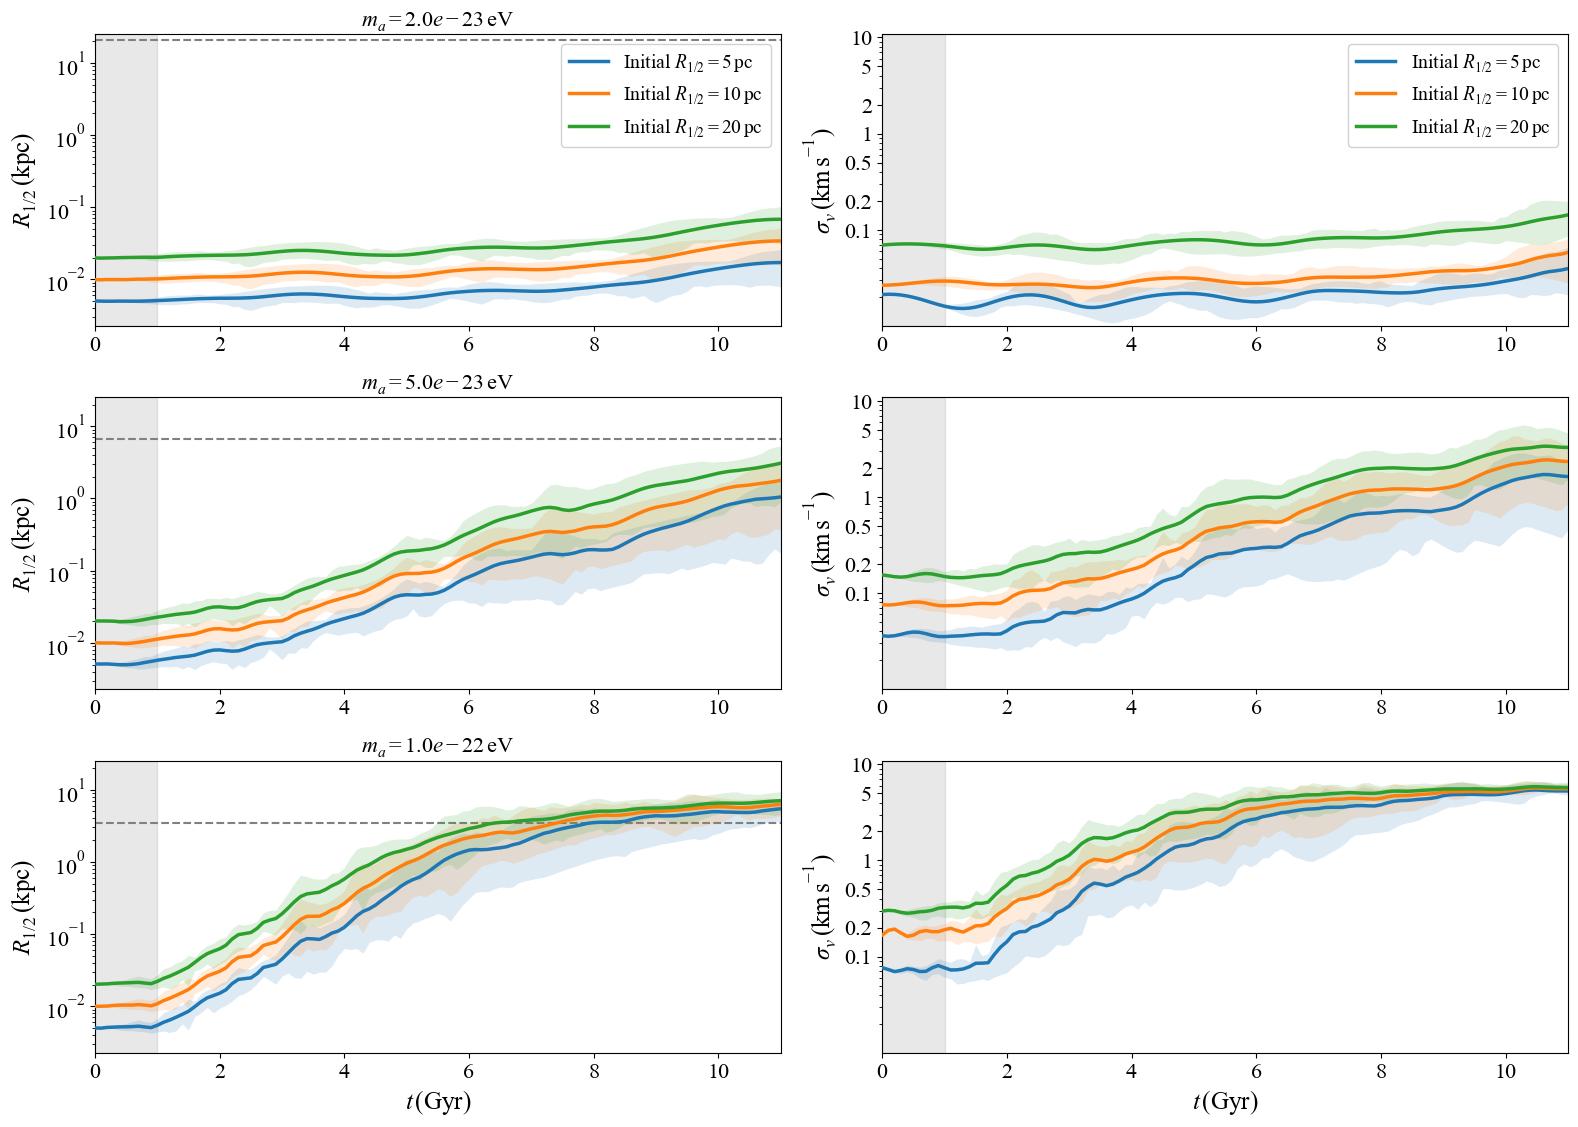

In [123]:
plt.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "font.size": 14,
        "axes.labelsize": 16,
        "axes.titlesize": 14,
        "legend.fontsize": 12,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "axes.unicode_minus": False,
    }
)

m_as = [0.2e-22, 0.5e-22, 1.0e-22]
have_soliton = True
M = 1e9
t_step = 0.1
seeds = np.arange(20)
rsigma_root = resolve_rsigma_root()

R_ic_list = ["5pc", "10pc", "20pc"]
R_ic_colors = {"5pc": "#1f77b4", "10pc": "#ff7f0e", "20pc": "#2ca02c"}
R_ic_labels = {
    "5pc": r"Initial $R_{1/2}=5\,\mathrm{pc}$",
    "10pc": r"Initial $R_{1/2}=10\,\mathrm{pc}$",
    "20pc": r"Initial $R_{1/2}=20\,\mathrm{pc}$",
}

results = {ric: {"k_r": [], "k_v": []} for ric in R_ic_list}

fig, axes = plt.subplots(len(m_as), 2, figsize=(16, 4 * len(m_as)))

global_r_min, global_r_max = np.inf, 0.0
global_v_min, global_v_max = np.inf, 0.0
soliton_radii = []

for idx, m_a in enumerate(m_as):
    r_trans = compute_soliton_core_radius(m_a, M=M)
    if have_soliton:
        soliton_radii.append(float(r_trans))

    dataset_name = f"ma{m_a:.1e}M{M:.1e}ts{t_step}rres512"
    if not have_soliton:
        dataset_name += "_nosoliton"

    ax_r, ax_v = axes[idx]

    for r_ic in R_ic_list:
        all_r, all_v, all_t = collect_rsigma_for_case(rsigma_root, dataset_name, seeds, r_ic)

        if not all_r:
            results[r_ic]["k_r"].append(np.nan)
            results[r_ic]["k_v"].append(np.nan)
            continue

        min_len = min(len(series) for series in all_r)
        r_stack = np.array([series[:min_len] for series in all_r], dtype=float)
        v_stack = np.array([series[:min_len] for series in all_v], dtype=float)
        t_ref = trimmed_time(all_t, min_len)

        r_p16 = np.percentile(r_stack, 16, axis=0)
        r_p84 = np.percentile(r_stack, 84, axis=0)
        v_p16 = np.percentile(v_stack, 16, axis=0)
        v_p84 = np.percentile(v_stack, 84, axis=0)

        ax_r.fill_between(t_ref, r_p16, r_p84, color=R_ic_colors[r_ic], alpha=0.15, linewidth=0, zorder=2)
        ax_v.fill_between(t_ref, v_p16, v_p84, color=R_ic_colors[r_ic], alpha=0.15, linewidth=0, zorder=2)

        mean_r = np.mean(r_stack, axis=0)
        mean_v = np.mean(v_stack, axis=0)

        ax_r.plot(
            t_ref,
            mean_r,
            color=R_ic_colors[r_ic],
            lw=2.5,
            label=R_ic_labels[r_ic] if idx == 0 else "",
            zorder=10,
        )
        ax_v.plot(
            t_ref,
            mean_v,
            color=R_ic_colors[r_ic],
            lw=2.5,
            label=R_ic_labels[r_ic] if idx == 0 else "",
            zorder=10,
        )

        k_r, _, _ = fit_growth_and_plateau(t_ref, mean_r, r_trans)
        k_v, _, _ = fit_growth_and_plateau(t_ref, mean_v, r_trans)
        results[r_ic]["k_r"].append(k_r)
        results[r_ic]["k_v"].append(k_v)

        r_pos = r_stack[r_stack > 0]
        v_pos = v_stack[v_stack > 0]
        if r_pos.size:
            global_r_min = min(global_r_min, float(np.min(r_pos)))
            global_r_max = max(global_r_max, float(np.max(r_pos)))
        if v_pos.size:
            global_v_min = min(global_v_min, float(np.min(v_pos)))
            global_v_max = max(global_v_max, float(np.max(v_pos)))

        if r_ic == "5pc":
            ax_r.axhline(
                r_trans,
                color="gray",
                ls="--",
                linewidth=1.5,
                label=None,
            )

    ax_r.set_ylabel(r"$R_{1/2}\,(\mathrm{kpc})$", fontsize=18)
    ax_v.set_ylabel(r"$\sigma_v\,(\mathrm{km\,s^{-1}})$", fontsize=18)
    ax_r.set_yscale("log")
    ax_v.set_yscale("log")
    ax_r.set_title(rf"$m_a = {m_a:.1e}\,\mathrm{{eV}}$", fontsize=16)

    if idx == len(m_as) - 1:
        ax_r.set_xlabel(r"$t\,(\mathrm{Gyr})$", fontsize=18)
        ax_v.set_xlabel(r"$t\,(\mathrm{Gyr})$", fontsize=18)

    ax_r.set_xlim(0, 11)
    ax_v.set_xlim(0, 11)
    ax_r.axvspan(0.0, 1.0, color="gray", alpha=0.18, zorder=0)
    ax_v.axvspan(0.0, 1.0, color="gray", alpha=0.18, zorder=0)

    ax_r.tick_params(labelsize=16)
    ax_v.tick_params(labelsize=16)

if not np.isfinite(global_r_min):
    global_r_min, global_r_max = 1e-3, 1e1
if not np.isfinite(global_v_min):
    global_v_min, global_v_max = 1e-2, 1e1

r_upper = global_r_max
if have_soliton and soliton_radii:
    r_upper = max(r_upper, max(soliton_radii))

r_ylim = (max(global_r_min * 0.8, 1e-4), r_upper * 1.2)
v_ylim = (max(global_v_min * 0.8, 1e-2), max(global_v_max * 1.15, 10.0))
sigma_ticks = [tick for tick in [0.1, 0.2, 0.5, 1, 2, 5, 10] if v_ylim[0] <= tick <= v_ylim[1]]

for idx in range(len(m_as)):
    axes[idx, 0].set_ylim(*r_ylim)
    axes[idx, 1].set_ylim(*v_ylim)
    if sigma_ticks:
        axes[idx, 1].set_yticks(sigma_ticks)
        axes[idx, 1].set_yticklabels([f"{tick:g}" for tick in sigma_ticks])

axes[0, 0].legend(loc="best", frameon=True, framealpha=0.9, fontsize=14)
axes[0, 1].legend(loc="best", frameon=True, framealpha=0.9, fontsize=14)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.savefig(FIGURES_DIR / "plot_e_selected_masses_main_fit.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Plot F: Tidal Comparison Across n_max

20pc


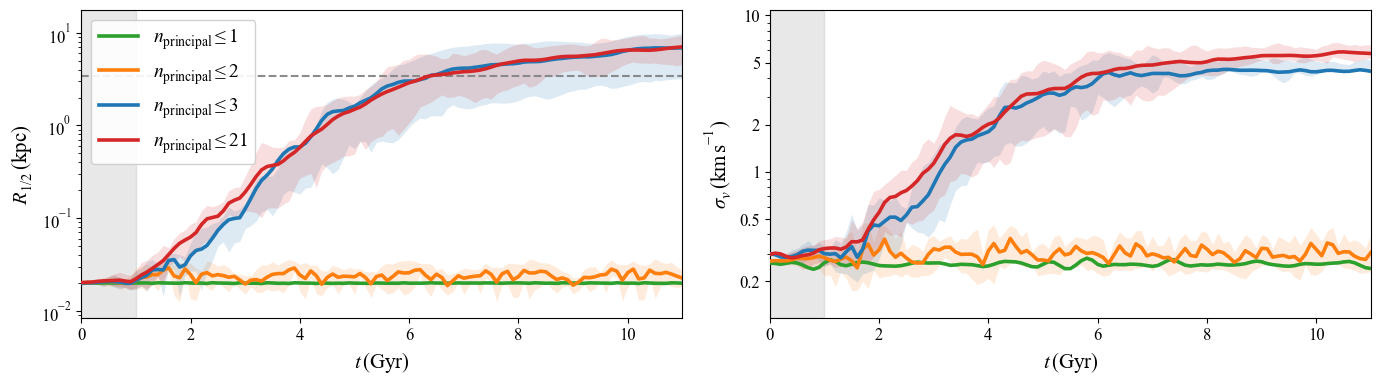

In [124]:
plt.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "font.size": 13,
        "axes.labelsize": 15,
        "axes.titlesize": 14,
        "legend.fontsize": 11,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "axes.unicode_minus": False,
    }
)

m_a = 1.0e-22
M = 1e9
t_step = 0.1
seeds = np.arange(20)
r_ic = "20pc"
print(r_ic)

base_folder = f"ma{m_a:.1e}M{M:.1e}ts{t_step}rres512"
folders = {
    r"$n_\text{principal}\leq1$": base_folder + "_Nmax1",
    r"$n_\text{principal}\leq2$": base_folder + "_Nmax2",
    r"$n_\text{principal}\leq3$": base_folder + "_Nmax3",
    r"$n_\text{principal}\leq21$": base_folder,
}

case_colors = {
    r"$n_\text{principal}\leq1$": "#2ca02c",
    r"$n_\text{principal}\leq2$": "#ff7f0e",
    r"$n_\text{principal}\leq3$": "#1f77b4",
    r"$n_\text{principal}\leq21$": "#d62728",
}

r_core = compute_soliton_core_radius(m_a, M=M)
rsigma_root = resolve_rsigma_root()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax_r, ax_v = axes

global_r_min, global_r_max = np.inf, 0.0
global_v_min, global_v_max = np.inf, 0.0

for case, dataset_name in folders.items():
    all_r, all_v, all_t = collect_rsigma_for_case(rsigma_root, dataset_name, seeds, r_ic)
    if len(all_r) == 0:
        continue

    min_len = min(len(series) for series in all_r)
    r_stack = np.array([series[:min_len] for series in all_r], dtype=float)
    v_stack = np.array([series[:min_len] for series in all_v], dtype=float)
    t_ref = trimmed_time(all_t, min_len)

    r_p16 = np.percentile(r_stack, 16, axis=0)
    r_p84 = np.percentile(r_stack, 84, axis=0)
    v_p16 = np.percentile(v_stack, 16, axis=0)
    v_p84 = np.percentile(v_stack, 84, axis=0)

    ax_r.fill_between(t_ref, r_p16, r_p84, color=case_colors[case], alpha=0.15, linewidth=0, zorder=2)
    ax_v.fill_between(t_ref, v_p16, v_p84, color=case_colors[case], alpha=0.15, linewidth=0, zorder=2)

    mean_r = np.mean(r_stack, axis=0)
    mean_v = np.mean(v_stack, axis=0)

    ax_r.plot(t_ref, mean_r, color=case_colors[case], lw=2.6, zorder=10, label=case)
    ax_v.plot(t_ref, mean_v, color=case_colors[case], lw=2.6, zorder=10, label=case)

    r_pos = r_stack[r_stack > 0]
    v_pos = v_stack[v_stack > 0]
    if r_pos.size:
        global_r_min = min(global_r_min, float(np.min(r_pos)))
        global_r_max = max(global_r_max, float(np.max(r_pos)))
    if v_pos.size:
        global_v_min = min(global_v_min, float(np.min(v_pos)))
        global_v_max = max(global_v_max, float(np.max(v_pos)))

if not np.isfinite(global_r_min):
    global_r_min, global_r_max = 1e-3, 1e1
if not np.isfinite(global_v_min):
    global_v_min, global_v_max = 1e-2, 1e1

r_ylim = (max(global_r_min * 0.8, 1e-4), global_r_max * 1.2)
v_ylim = (max(global_v_min * 0.8, 1e-2), max(global_v_max * 1.15, 10.0))
sigma_ticks = [tick for tick in [0.1, 0.2, 0.5, 1, 2, 5, 10] if v_ylim[0] <= tick <= v_ylim[1]]

ax_r.set_yscale("log")
ax_v.set_yscale("log")
ax_r.set_ylim(*r_ylim)
ax_v.set_ylim(*v_ylim)
if sigma_ticks:
    ax_v.set_yticks(sigma_ticks)
    ax_v.set_yticklabels([f"{tick:g}" for tick in sigma_ticks])

ax_r.set_ylabel(r"$R_{1/2}\,(\mathrm{kpc})$")
ax_v.set_ylabel(r"$\sigma_v\,(\mathrm{km\,s^{-1}})$")

ax_r.set_xlabel(r"$t\,(\mathrm{Gyr})$")
ax_v.set_xlabel(r"$t\,(\mathrm{Gyr})$")
ax_r.set_xlim(0, 11)
ax_v.set_xlim(0, 11)
ax_r.axvspan(0.0, 1.0, color="gray", alpha=0.18, zorder=0)
ax_v.axvspan(0.0, 1.0, color="gray", alpha=0.18, zorder=0)

ax_r.axhline(r_core, color="gray", linestyle="--", linewidth=1.5, alpha=0.9)

ax_r.legend(loc="upper left", frameon=True, framealpha=0.9, fontsize=14)

plt.tight_layout(rect=[0, 0.16, 1, 1])
plt.savefig(FIGURES_DIR / "plot_f_tidal_n_comparison_ma1e-22.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Plot G: Particle Spatial Distribution on Projected FDM Density (m_a=1e-22, Nmax=21, seed=0)

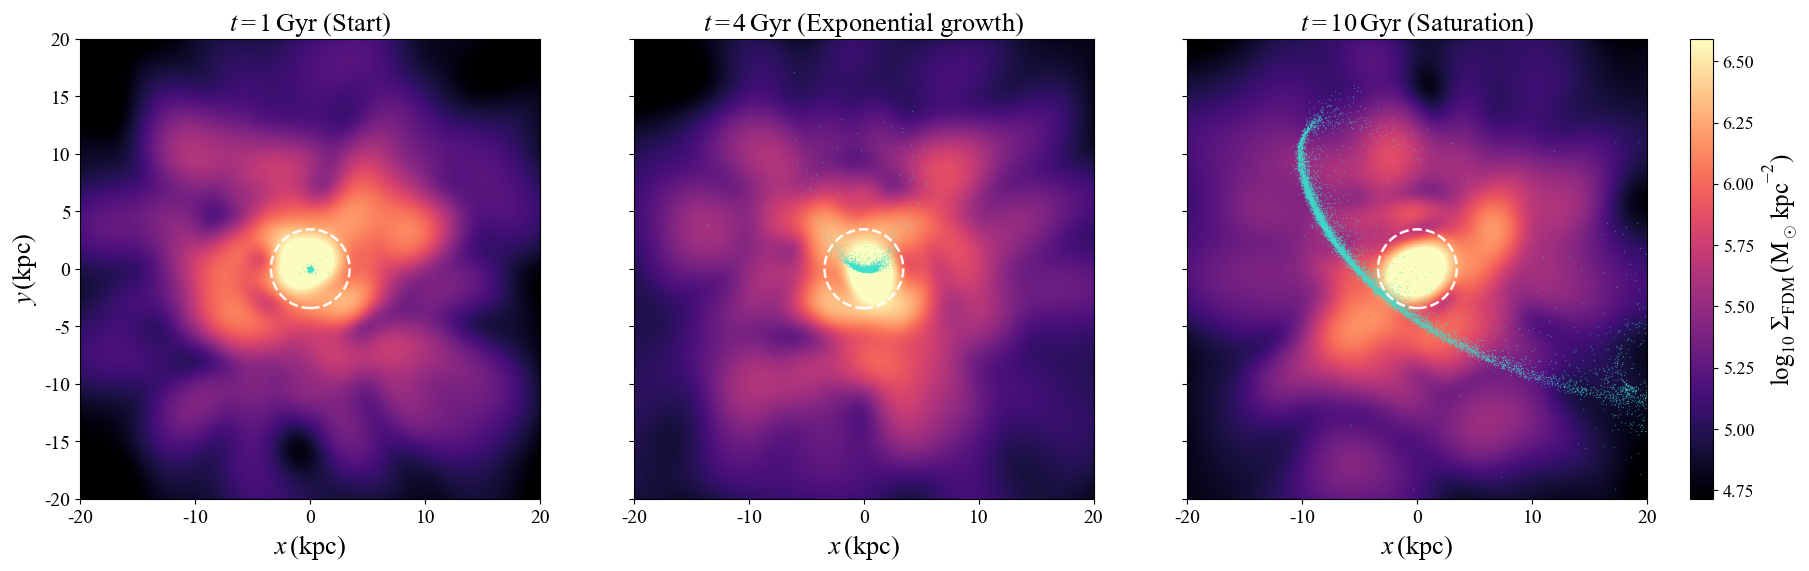

In [125]:
import agama as ag

ag.setUnits(mass=1, length=1, velocity=1)

m_a = 1.0e-22
M = 1e9
seed = 0
R_ic = "20pc"  # switch to "5pc" or "10pc" if needed
t_step = 0.1
ramp_up = 10

# Colors tuned for better contrast against the magma background.
particle_color = "#40E0D0"
soliton_circle_color = "white"

times_gyr = [1.0, 4.0, 10.0]
stage_labels = ["Start", "Exponential growth", "Saturation"]

case_dir = Path("ma1.0e-22M1.0e+09ts0.1rres512") / f"s{seed}"
xvta_path = case_dir / f"xvta_Ric{R_ic}.npz"
density_dir = case_dir

if not xvta_path.exists():
    raise FileNotFoundError(f"Missing xvta file: {xvta_path}")
if not (density_dir / "sph_harm_gradual000.ini").exists():
    raise FileNotFoundError(f"Missing density files in: {density_dir}")

with np.load(xvta_path) as data:
    xvta = data["xvta"]

r_core = compute_soliton_core_radius(m_a, M=M)


def load_density_snapshot(snapshot_idx: int):
    gradual_path = density_dir / f"sph_harm_gradual{snapshot_idx:03d}.ini"
    if not gradual_path.exists():
        raise FileNotFoundError(f"Missing density snapshot file: {gradual_path}")

    if snapshot_idx < ramp_up:
        base_path = density_dir / f"sph_harm_base_gradual{snapshot_idx:03d}.ini"
        if not base_path.exists():
            raise FileNotFoundError(f"Missing base density snapshot file: {base_path}")
        den1 = ag.Density(str(gradual_path))
        den2 = ag.Density(str(base_path))
        return ag.Density(den1, den2)

    return ag.Density(str(gradual_path))


def projected_density_map(den, half_box_kpc: float, ngrid: int = 320):
    x = np.linspace(-half_box_kpc, half_box_kpc, ngrid)
    y = np.linspace(-half_box_kpc, half_box_kpc, ngrid)
    xx, yy = np.meshgrid(x, y, indexing="xy")
    points_xy = np.column_stack((xx.ravel(), yy.ravel()))

    pot = ag.Potential(type="multipole", density=den, lmax=20, rmin=0.0001, rmax=30)
    sigma = pot.projectedDensity(points_xy).reshape(ngrid, ngrid)
    sigma = np.maximum(sigma, 1e-30)
    return np.log10(sigma)


snapshot_indices = [int(round(t / t_step)) for t in times_gyr]
if max(snapshot_indices) >= xvta.shape[0]:
    raise ValueError(
        f"Requested snapshot index {max(snapshot_indices)} exceeds xvta size {xvta.shape[0]}"
    )

selected_x = np.concatenate([xvta[idx, 0] for idx in snapshot_indices])
selected_y = np.concatenate([xvta[idx, 1] for idx in snapshot_indices])
selected_r = np.sqrt(selected_x**2 + selected_y**2)
half_box = float(np.percentile(selected_r, 99.9) * 1.15)
half_box = float(np.clip(half_box, 0.3, 20.0))

log_sigma_maps = []
for idx in snapshot_indices:
    den = load_density_snapshot(idx)
    log_sigma_maps.append(projected_density_map(den, half_box_kpc=half_box, ngrid=320))

vmin = min(np.percentile(m, 5) for m in log_sigma_maps)
vmax = max(np.percentile(m, 99) for m in log_sigma_maps)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), sharex=True, sharey=True, constrained_layout=True)

im = None
for ax, t_now, idx, stage, log_sigma in zip(axes, times_gyr, snapshot_indices, stage_labels, log_sigma_maps):
    im = ax.imshow(
        log_sigma,
        origin="lower",
        extent=[-half_box, half_box, -half_box, half_box],
        cmap="magma",
        vmin=vmin,
        vmax=vmax,
        aspect="equal",
    )

    ax.scatter(
        xvta[idx, 0],
        xvta[idx, 1],
        s=1.0,
        c=particle_color,
        alpha=0.40,
        linewidths=0.0,
        rasterized=True,
    )

    soliton_circle = plt.Circle(
        (0.0, 0.0),
        r_core,
        edgecolor=soliton_circle_color,
        facecolor="none",
        linestyle="--",
        linewidth=1.8,
        alpha=0.95,
    )
    ax.add_patch(soliton_circle)

    ax.set_title(rf"$t={t_now:g}\,\mathrm{{Gyr}}$ ({stage})", fontsize=19)
    ax.set_xlabel(r"$x\,(\mathrm{kpc})$", fontsize=19)
    ax.set_xlim(-half_box, half_box)
    ax.set_ylim(-half_box, half_box)
    ax.tick_params(labelsize=14)

axes[0].set_ylabel(r"$y\,(\mathrm{kpc})$", fontsize=19)

cbar = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02)
cbar.set_label(r"$\log_{10}\,\Sigma_{\mathrm{FDM}}\,(\mathrm{M_\odot\,kpc^{-2}})$", fontsize=18)
cbar.ax.tick_params(labelsize=13)

plt.savefig(FIGURES_DIR / "plot_g_projected_cluster_evolution_ma1e-22.png", dpi=300, bbox_inches="tight")
plt.show()